## **Double gyre flow**

In [2]:
%load_ext autoreload
%autoreload 2

In [3]:
# IMPORT LIBRARIES

import torch
import numpy as np
import matplotlib.pyplot as plt

import warnings
warnings.filterwarnings("ignore", category = DeprecationWarning)
import sys
import os
from pathlib import Path
# Add parent directory to path to access src module
sys.path.insert(0, str(Path.cwd().parent.parent))
from src.train import fit as fit_model
from src.train import evaluate as evaluate_model
from src.mSHRED.mSRED import mSHRED

# get device
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

np.random.seed(2025)

from helpers import DGFsimulation

## Simulator

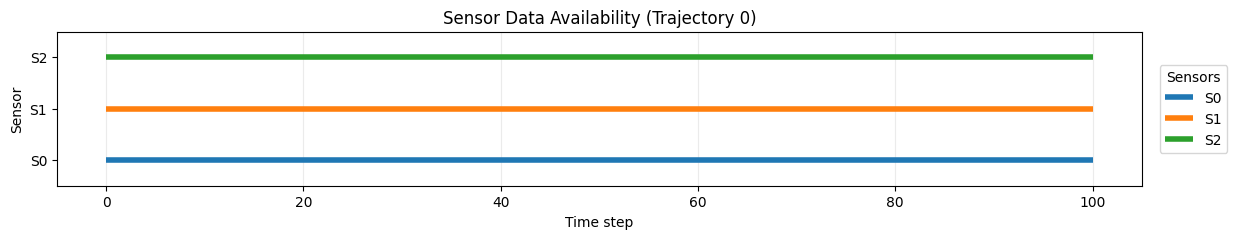

Shape of U:	 (100, 101, 1250) 	Shape of Uraw:	 (100, 101, 50, 25)
Shape of V:	 (100, 101, 1250) 	Shape of Vraw:	 (100, 101, 50, 25)
measurements:	 (100, 101, 3)


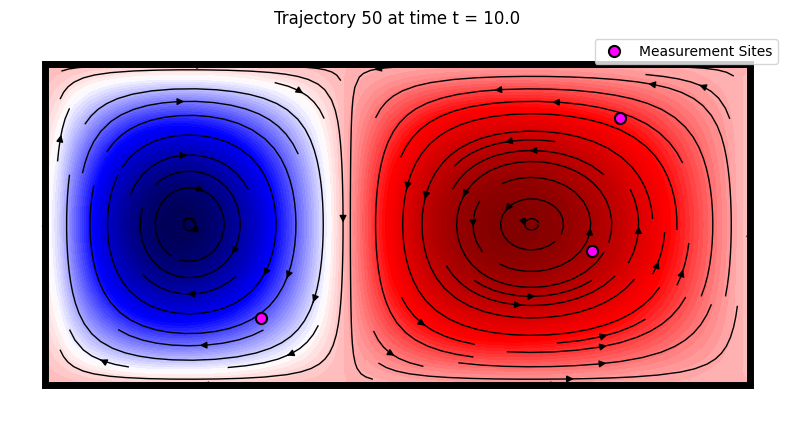

In [4]:
# generate DGF data 
simulator    = DGFsimulation(ntrajectories=100)
Uraw, Vraw   = simulator.generate_data()
U, V         = simulator.get_reshaped_data()
measurements = simulator.generate_measurements_U(
    nsensors=3, idx_short_broken=[], idx_long_broken=[], verbose=True, positions=[ 960,  380, 1020]
)

# Debugging 
print("Shape of U:\t", U.shape, "\tShape of Uraw:\t", Uraw.shape)
print("Shape of V:\t", V.shape, "\tShape of Vraw:\t", Vraw.shape)
print("measurements:\t", measurements.shape)
simulator.plot_data(which_trajectory=50)

## POD

In [5]:
# TRAIN-VALIDATION SPLITTING

split_ratio = 0.8
ntrajectories = U.shape[0]
ntimes = U.shape[1]
nstate = U.shape[2]

ntrain = round(split_ratio * ntrajectories)

idx_train = np.random.choice(ntrajectories, size = ntrain, replace = False)
mask = np.ones(ntrajectories)
mask[idx_train] = 0
idx_valid_test = np.arange(0, ntrajectories)[np.where(mask!=0)[0]]
idx_valid = idx_valid_test[::2]
idx_test = idx_valid_test[1::2]

nvalid = idx_valid.shape[0]
ntest = idx_test.shape[0]

Utrain = U[idx_train]
Uvalid = U[idx_valid]
Utest = U[idx_test]

Vtrain = V[idx_train]
Vvalid = V[idx_valid]
Vtest = V[idx_test]

In [6]:
# DIMENSIONALITY REDUCTION - HORIZONTAL VELOCITY

Utrain = Utrain.reshape(-1, nstate)
Uvalid = Uvalid.reshape(-1, nstate)
Utest = Utest.reshape(-1, nstate)

U1_POD, S1_POD, V1_POD = np.linalg.svd(Utrain, full_matrices = False)
POD_modes = 4

Utrain_proj = Utrain @ V1_POD[:POD_modes, :].T
Utrain_proj = Utrain_proj.reshape(ntrain, ntimes, POD_modes)
Utrain = Utrain.reshape(ntrain, ntimes, nstate)

Uvalid_proj = Uvalid @ V1_POD[:POD_modes, :].T
Uvalid_proj = Uvalid_proj.reshape(nvalid, ntimes, POD_modes)
Uvalid = Uvalid.reshape(nvalid, ntimes, nstate)

Utest_proj = Utest @ V1_POD[:POD_modes, :].T
Utest_proj = Utest_proj.reshape(ntest, ntimes, POD_modes)
Utest = Utest.reshape(ntest, ntimes, nstate)

print(f"Residual energy is equal to  {np.sum(S1_POD[POD_modes:]**2) / np.sum(S1_POD**2)}\n")

Residual energy is equal to  6.265534916861889e-07



In [7]:
# DIMENSIONALITY REDUCTION - VERTICAL VELOCITY

Vtrain = Vtrain.reshape(-1, nstate)
Vvalid = Vvalid.reshape(-1, nstate)
Vtest = Vtest.reshape(-1, nstate)

U2_POD, S2_POD, V2_POD = np.linalg.svd(Vtrain, full_matrices = False)
POD_modes = 4

Vtrain_proj = Vtrain @ V2_POD[:POD_modes, :].T
Vtrain_proj = Vtrain_proj.reshape(ntrain, ntimes, POD_modes)
Vtrain = Vtrain.reshape(ntrain, ntimes, nstate)

Vvalid_proj = Vvalid @ V2_POD[:POD_modes, :].T
Vvalid_proj = Vvalid_proj.reshape(nvalid, ntimes, POD_modes)
Vvalid = Vvalid.reshape(nvalid, ntimes, nstate)

Vtest_proj = Vtest @ V2_POD[:POD_modes, :].T
Vtest_proj = Vtest_proj.reshape(ntest, ntimes, POD_modes)
Vtest = Vtest.reshape(ntest, ntimes, nstate)

print(f"Residual energy is equal to  {np.sum(S2_POD[POD_modes:]**2) / np.sum(S2_POD**2)}\n")

Residual energy is equal to  5.35515202865115e-06



## SHRED

In [8]:
# DEFINE FUNCTION TO PROCESS DATA

class TimeSeriesDataset(torch.utils.data.Dataset):
    def __init__(self, X, Y):
        self.X = X
        self.Y = Y
        self.len = X.shape[0]

    def __getitem__(self, index):
        return self.X[index], self.Y[index]

    def __len__(self):
        return self.len


def Padding(data, lag):
    data_out = torch.zeros(data.shape[0] * data.shape[1], lag, data.shape[2])

    for i in range(data.shape[0]):
        for j in range(1, data.shape[1] + 1):
            if j < lag:
                data_out[i * data.shape[1] + j - 1, -j:] = data[i, :j]
            else:
                data_out[i * data.shape[1] + j - 1] = data[i, j - lag : j]

    return data_out

In [9]:
# BUILD TRAIN, VALIDATION AND TEST DATASETS WITH PADDING

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

lag = 25

sensors_data_train = torch.from_numpy(measurements[idx_train]).float()
sensors_data_valid = torch.from_numpy(measurements[idx_valid]).float()
sensors_data_test = torch.from_numpy(measurements[idx_test]).float()
Utrain_proj = torch.from_numpy(Utrain_proj).float()
Vtrain_proj = torch.from_numpy(Vtrain_proj).float()
Uvalid_proj = torch.from_numpy(Uvalid_proj).float()
Vvalid_proj = torch.from_numpy(Vvalid_proj).float()
Utest_proj = torch.from_numpy(Utest_proj).float()
Vtest_proj = torch.from_numpy(Vtest_proj).float()

train_data_in = Padding(sensors_data_train, lag).to(device)
valid_data_in = Padding(sensors_data_valid, lag).to(device)
test_data_in = Padding(sensors_data_test, lag).to(device)

train_data_out = Padding(torch.cat((Utrain_proj, Vtrain_proj), 2), 1).squeeze(1).to(device)
valid_data_out = Padding(torch.cat((Uvalid_proj, Vvalid_proj), 2), 1).squeeze(1).to(device)
test_data_out = Padding(torch.cat((Utest_proj, Vtest_proj), 2), 1).squeeze(1).to(device)

train_dataset = TimeSeriesDataset(train_data_in, train_data_out)
valid_dataset = TimeSeriesDataset(valid_data_in, valid_data_out)
test_dataset = TimeSeriesDataset(test_data_in, test_data_out)

print("Shape of train data in:\t", train_data_in.shape, "\tShape of train data out:\t", train_data_out.shape)
print("Shape of valid data in:\t", valid_data_in.shape, "\tShape of valid data out:\t", valid_data_out.shape)
print("Shape of test data in:\t", test_data_in.shape, "\tShape of test data out:  \t", test_data_out.shape)

Shape of train data in:	 torch.Size([8080, 25, 3]) 	Shape of train data out:	 torch.Size([8080, 8])
Shape of valid data in:	 torch.Size([1010, 25, 3]) 	Shape of valid data out:	 torch.Size([1010, 8])
Shape of test data in:	 torch.Size([1010, 25, 3]) 	Shape of test data out:  	 torch.Size([1010, 8])


In [10]:
# mSHRED TRAINING
model_args = dict(
    # Encoder
    encoder="transformer", encoder_depth=1, input_size=3, n_heads=4,
    dim_feedforward=64, hidden_size=32, input_length=lag, double_channels = False,
    # Decoder
    decoder="mlp", decoder_hidden_sizes=[], output_size=8, dropout=0.1,
)
mshred = mSHRED(args=model_args).to(device)

train_errors, valid_errors = fit_model(
    mshred, train_dataset, valid_dataset,
    optimizer="AdamW", lr=1e-3, num_epochs=150, lr_scheduler="CosineAnnealingLR", scheduler_step_size=150, patience=40, verbose=True,
)

Starting training...


Training: 100%|██████████| 150/150 [04:57<00:00,  1.98s/it, Train Loss=0.0014, Val Loss=0.0024, Patience=33, Best Val Loss=0.0022, LR=0.00e+00]

Training completed with best validation loss: 0.0022


,model,type,train-mse,val-mse,test-mse,train-mre,val-mre,test-mre
0,(mSHRED): TR + MLP,(T.0) only available sensors,0.001246,0.002223,0.001792,0.011117,0.014074,0.012729


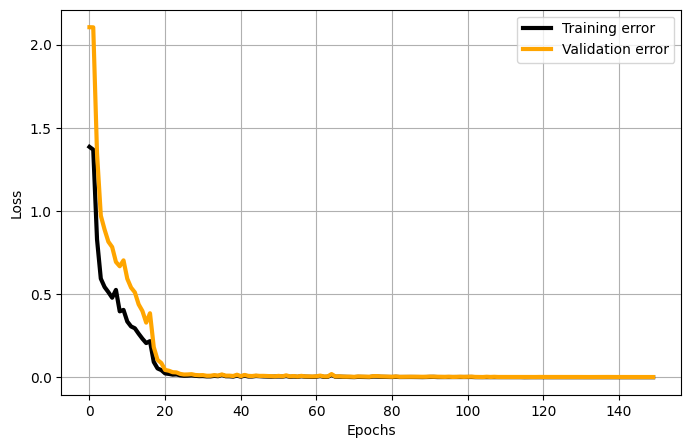

In [11]:
# TRAINING HISTORY VISUALIZATION

plt.figure(figsize = (8,5))
plt.plot(train_errors, 'k', linewidth = 3, label = 'Training error')
plt.plot(valid_errors, 'orange', linewidth = 3, label = 'Validation error')
plt.xlabel('Epochs')
plt.ylabel('Loss')
plt.legend()
plt.grid(True)

train_mse , train_mre = evaluate_model(mshred, train_dataset)
valid_mse , valid_mre = evaluate_model(mshred, valid_dataset)
test_mse , test_mre = evaluate_model(mshred, test_dataset)
test_error = {
    "model": f"(mSHRED): TR + MLP", "type" : "(T.0) only available sensors",
    "train-mse": float(train_mse), "val-mse": float(valid_mse),"test-mse": float(test_mse), 
    "train-mre": float(train_mre), "val-mre": float(valid_mre), "test-mre": float(test_mre),
}

# Save errors to dataframe
import pandas as pd
ERRORS = []
ERRORS.append(test_error)
dataframe_errors = pd.DataFrame(ERRORS)
display(dataframe_errors)
dataframe_errors.to_csv("dataframe_errors.csv", index=False)

Mean Relative Error (MRE): 	U: 1.255%	V: 1.311%


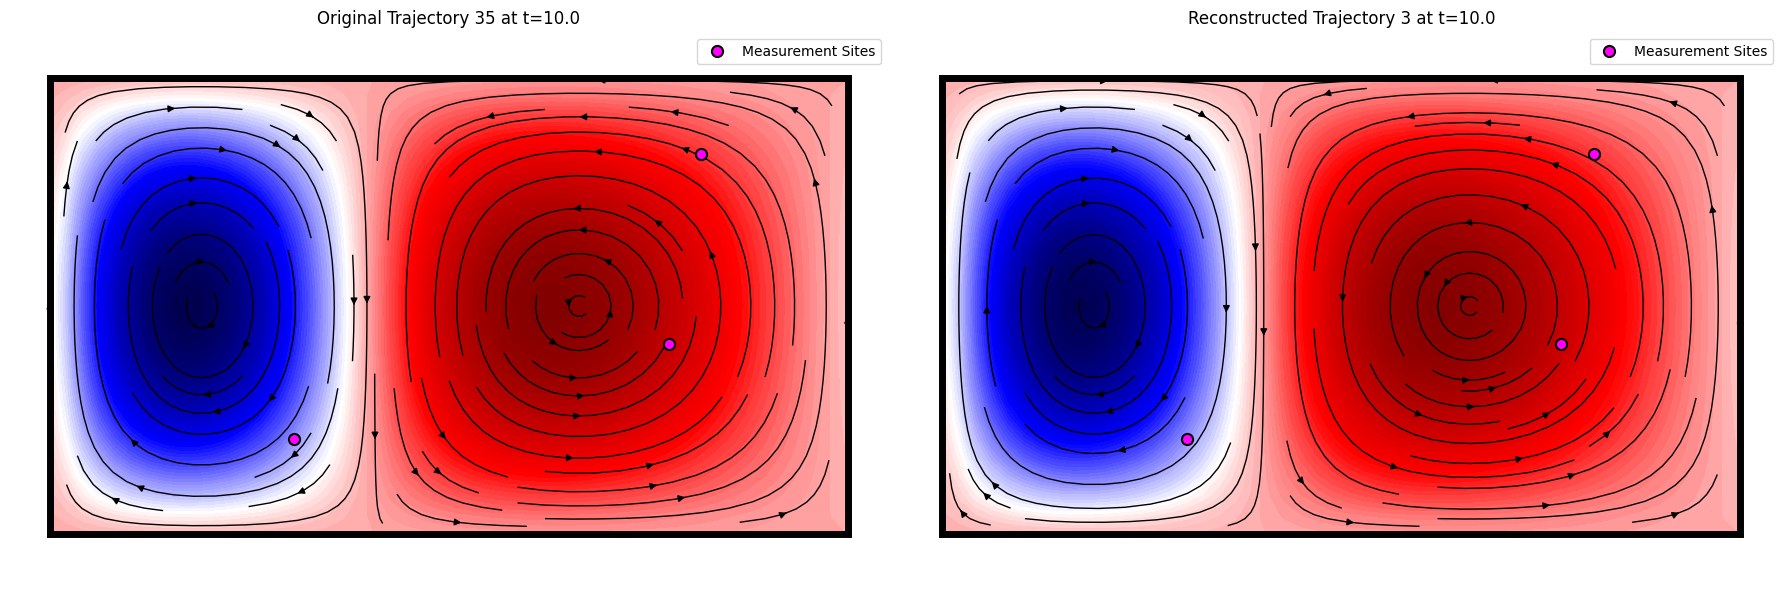

In [12]:
mshred.freeze()
UVtest_hat = mshred(test_data_in).cpu().to(torch.float64)
test_reconstruction = {}
test_reconstruction["U"] = UVtest_hat[:,:POD_modes] @ V1_POD[:POD_modes, :]
test_reconstruction["V"] = UVtest_hat[:,POD_modes:] @ V2_POD[:POD_modes, :]

simulator.plot_comparison(test_reconstruction, test_idx = idx_test, which_trajectory=3)